# ECG Image Classification: Machine Learning Cycle (MLOps)

**Use case.** This builds on my Introduction to ML summative, where I predicted cardiovascular disease from a table of patient measurements (best test ROC-AUC about 0.80). Here the same problem is tackled with **images**: scanned 12-lead ECG printouts.

**Data.** ECG Images dataset of Cardiac Patients (Khan and Hussain, Mendeley Data, v2). One ECG sheet per patient, 928 sheets, four classes: `Normal`, `Abnormal_Heartbeat`, `MI` (myocardial infarction) and `History_of_MI`.

**Final model.** The ECG trace is extracted from each sheet, described with HOG (histogram of oriented gradients) features, reduced with PCA, and classified by a neural network (multi-layer perceptron) trained with class weights, L2 regularisation, early stopping and best-weight restoring. Saved as `models/ecg_hog_mlp.pkl`.

The notebook covers data acquisition, data visualisation and interpretation, preprocessing, model creation, model testing, saving, the prediction function and a retraining check. The same code lives in `src/` and is used by the API and the UI, so the notebook and the deployed app behave the same way.

## 1. Setup

In [1]:
import os, sys, glob, json, random, shutil, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.stats import kruskal
import sklearn
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

warnings.filterwarnings('ignore')

# Make the repo's src/ package importable whether the notebook runs from notebook/ or the repo root
REPO = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebook' else os.getcwd()
sys.path.insert(0, REPO)
from src import config, preprocessing
from src.model import EcgClassifier, evaluate_model, load_model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# One fixed colour per class, used in every chart
CLASSES = ['Abnormal_Heartbeat', 'History_of_MI', 'MI', 'Normal']
COLORS = dict(zip(CLASSES, ['#257de0', '#f47230', '#00b894', '#f2a600']))
sns.set_theme(style='whitegrid', rc={'axes.edgecolor': '#cccccc', 'grid.color': '#eeeeee',
                                     'text.color': '#191919', 'axes.labelcolor': '#666666'})

print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__, '| numpy', np.__version__)

Python 3.13.18 | scikit-learn 1.9.1 | numpy 2.5.3


## 2. Data acquisition

The dataset was downloaded from https://data.mendeley.com/datasets/gwbz3fsgp8/2 ("Download All"), uploaded to Google Drive and unzipped in Colab. The cell below does that when it runs in Colab, then splits the images 80/20 into `data/train` and `data/test` (stratified, seed 42). Each image is a different patient, so no patient appears in both sets.

When the notebook runs from the repo (as it does here), the split already exists in `data/`, so it is reused. That keeps the test set identical to the one the deployed app reports on.

In [2]:
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    import zipfile
    from sklearn.model_selection import train_test_split
    from google.colab import drive
    drive.mount('/content/drive')
    ZIP_PATH = '/content/drive/MyDrive/gwbz3fsgp8-2 (1).zip'
    RAW_DIR = '/content/ecg_data'
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)
    rules = [('abnormal heartbeat', 'Abnormal_Heartbeat'), ('history of mi', 'History_of_MI'),
             ('myocardial infarction', 'MI'), ('normal person', 'Normal')]
    rows = []
    for root, _, files in os.walk(RAW_DIR):
        label = next((name for key, name in rules if key in os.path.basename(root).lower()), None)
        rows += [(os.path.join(root, f), label) for f in files if label and f.lower().endswith('.jpg')]
    raw = pd.DataFrame(rows, columns=['path', 'label'])
    tr, te = train_test_split(raw, test_size=0.2, stratify=raw['label'], random_state=SEED)
    for split, part in [('train', tr), ('test', te)]:
        for _, r in part.iterrows():
            dst = os.path.join(config.DATA_DIR, split, r['label'])
            os.makedirs(dst, exist_ok=True)
            shutil.copy(r['path'], dst)

train_paths, train_labels = preprocessing.list_images(config.TRAIN_DIR)
test_paths, test_labels = preprocessing.list_images(config.TEST_DIR)
df = pd.DataFrame({'path': train_paths + test_paths,
                   'label': train_labels + test_labels,
                   'split': ['train'] * len(train_paths) + ['test'] * len(test_paths)})

counts = pd.crosstab(df['label'], df['split'])[['train', 'test']]
counts['total'] = counts.sum(axis=1)
counts.loc['All'] = counts.sum()
display(counts)

split,train,test,total
label,,,
Abnormal_Heartbeat,186,47,233
History_of_MI,138,34,172
MI,191,48,239
Normal,227,57,284
All,742,186,928


## 3. Data visualisations and interpretation

I look at four things: how many examples each class has, how much heart trace is on each sheet, how tall the beats are in the rhythm strip, and what an average sheet of each class looks like. The two numeric features come from `preprocessing.describe_image`, which isolates the black trace from the pink grid first (explained in section 4).

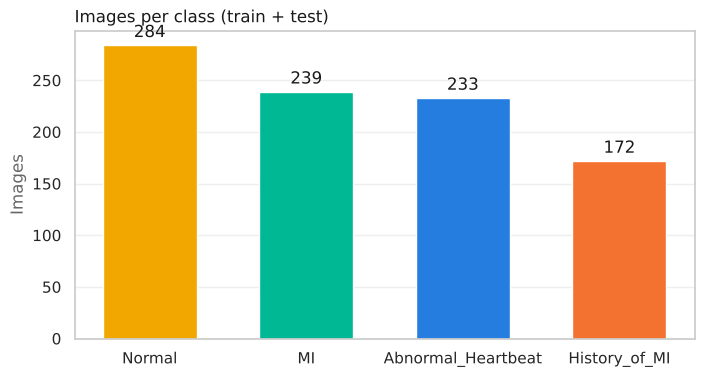

Largest/smallest class ratio: 1.65


In [3]:
# Visualisation 1: class distribution
order = df['label'].value_counts().index.tolist()
fig, ax = plt.subplots(figsize=(8, 4))
c = df['label'].value_counts().reindex(order)
bars = ax.bar(order, c.values, color=[COLORS[k] for k in order], width=0.6)
ax.bar_label(bars, padding=3, color='#191919')
ax.set_title('Images per class (train + test)', loc='left')
ax.set_ylabel('Images')
ax.grid(axis='x', visible=False)
plt.show()
print(f"Largest/smallest class ratio: {c.max() / c.min():.2f}")

**Interpretation 1: class balance.** `Normal` is the largest class (284 images) and `History_of_MI` the smallest (172), a ratio of about 1.65 to 1. That's a mild imbalance, but enough that a lazy model could lean towards `Normal` and still look decent on accuracy. So training uses balanced class weights, and I judge the model on macro precision, recall and F1, which weight every class equally, as well as on accuracy. The split is stratified, so the test set keeps the same proportions.

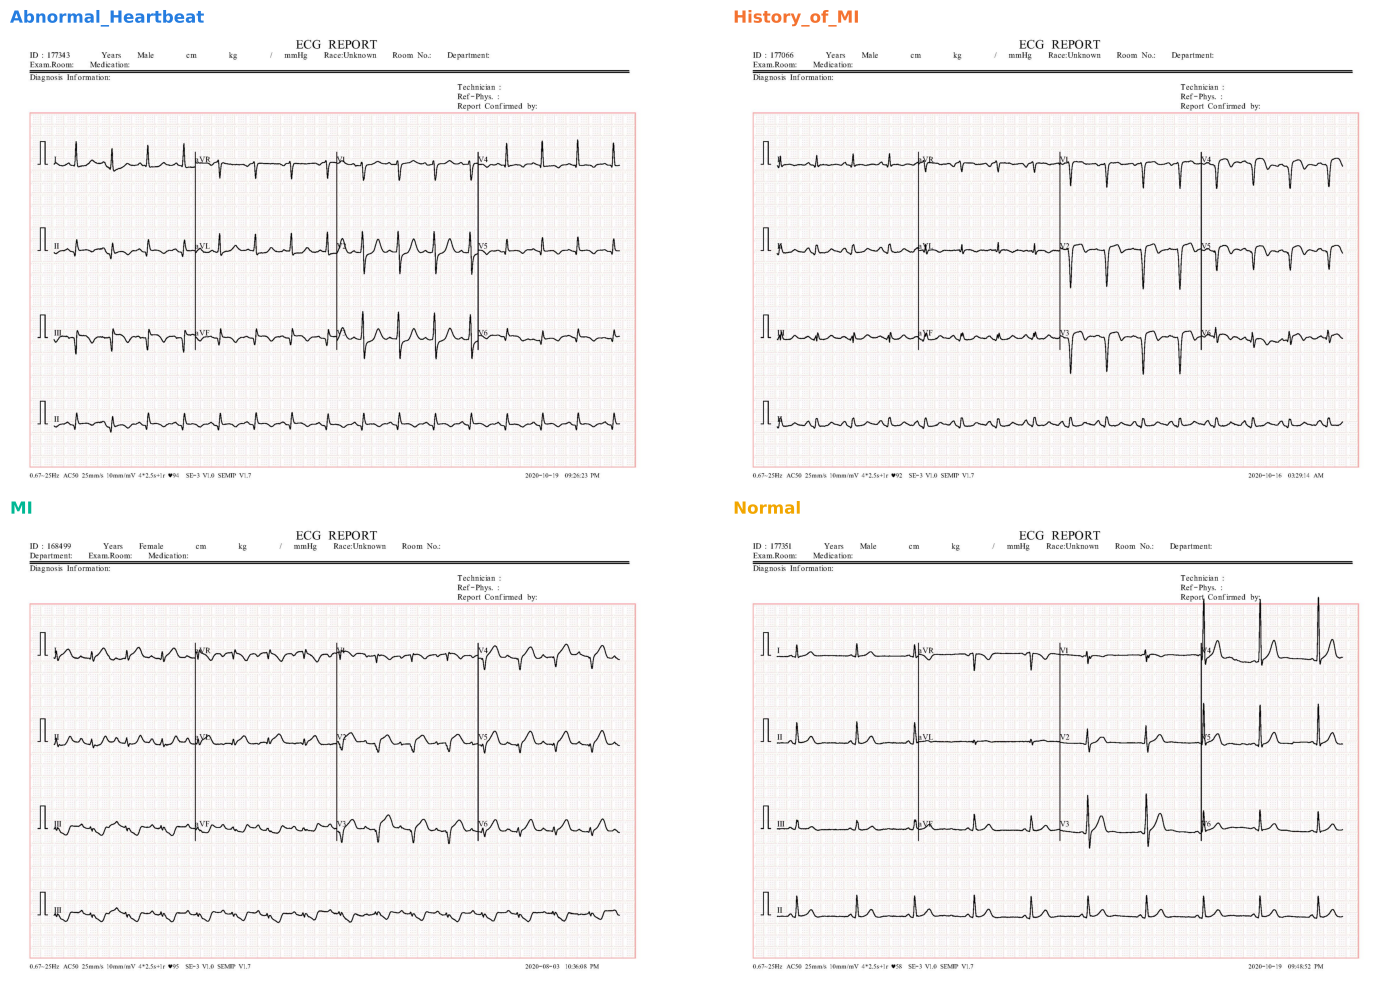

In [4]:
# What the raw sheets look like: one per class
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, cls in zip(axes.ravel(), CLASSES):
    p = df[df['label'] == cls].sample(1, random_state=SEED)['path'].iloc[0]
    ax.imshow(Image.open(p))
    ax.set_title(cls, loc='left', color=COLORS[cls], fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [5]:
# Interpretable features for every image (takes about a minute)
t0 = time.time()
feats = pd.DataFrame([preprocessing.describe_image(p) for p in df['path']])
df = pd.concat([df.reset_index(drop=True), feats], axis=1)
print(f'Computed in {time.time() - t0:.0f}s')
print('Distinct image sizes:', df[['width', 'height']].drop_duplicates().values.tolist())
summary = df.groupby('label')[['trace_ink_pct', 'rhythm_amplitude_px']].agg(['median', 'mean', 'std']).round(3)
display(summary)

Computed in 20s
Distinct image sizes: [[2213, 1572]]


trace_ink_pct               rhythm_amplitude_px                
                          median   mean    std              median    mean     std
label                                                                             
Abnormal_Heartbeat         3.343  3.464  0.541              66.000  89.816  62.780
History_of_MI              2.568  2.650  0.364              41.500  63.355  57.280
MI                         2.757  2.757  0.442              35.020  51.354  40.782
Normal                     2.630  2.635  0.230              37.255  44.187  33.403

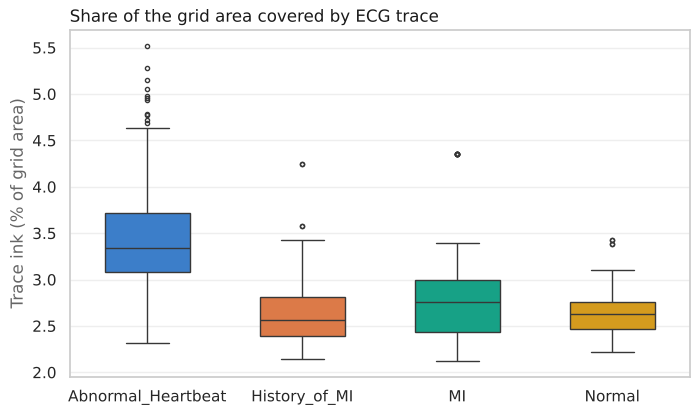

Kruskal-Wallis test across classes: H = 383.6, p = 7.8e-83
label
Abnormal_Heartbeat    3.34
History_of_MI         2.57
MI                    2.76
Normal                2.63


In [6]:
# Visualisation 2: trace ink density
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x='label', y='trace_ink_pct', order=CLASSES, palette=COLORS, width=0.55, fliersize=3, ax=ax)
ax.set_title('Share of the grid area covered by ECG trace', loc='left')
ax.set_xlabel('')
ax.set_ylabel('Trace ink (% of grid area)')
plt.show()
H, p = kruskal(*[df.loc[df['label'] == c, 'trace_ink_pct'] for c in CLASSES])
print(f'Kruskal-Wallis test across classes: H = {H:.1f}, p = {p:.2g}')
print(df.groupby('label')['trace_ink_pct'].median().round(2).to_string())

**Interpretation 2: trace ink density.** Sheets from `Abnormal_Heartbeat` patients carry clearly more trace: a median of 3.34% of the grid area, against 2.57 to 2.76% for the other three classes. The Kruskal-Wallis test (p around 1e-83) says that gap is far too large to be chance. It makes sense clinically. An abnormal rhythm usually means more beats per strip, extra or early beats, or wider complexes, and each of those puts more ink on the page. `History_of_MI`, `MI` and `Normal` overlap heavily, though, so ink density can pick out abnormal rhythms but can't tell the other three apart. The model needs information about *shape*, not just quantity.

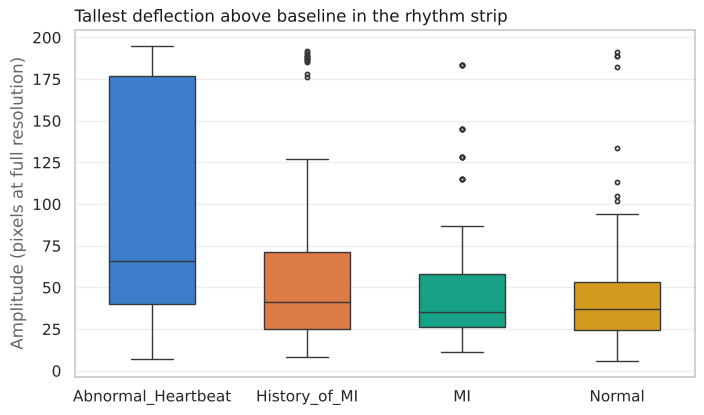

Kruskal-Wallis test across classes: H = 96.1, p = 1.1e-20
label
Abnormal_Heartbeat    0.27
History_of_MI         0.15
MI                    0.03
Normal                0.03


In [7]:
# Visualisation 3: beat height in the lead II rhythm strip
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x='label', y='rhythm_amplitude_px', order=CLASSES, palette=COLORS, width=0.55, fliersize=3, ax=ax)
ax.set_title('Tallest deflection above baseline in the rhythm strip', loc='left')
ax.set_xlabel('')
ax.set_ylabel('Amplitude (pixels at full resolution)')
plt.show()
H, p = kruskal(*[df.loc[df['label'] == c, 'rhythm_amplitude_px'] for c in CLASSES])
print(f'Kruskal-Wallis test across classes: H = {H:.1f}, p = {p:.2g}')
print((df['rhythm_amplitude_px'] > 150).groupby(df['label']).mean().round(2).rename('share above 150 px').to_string())

**Interpretation 3: beat height in the rhythm strip.** In the lead II strip at the bottom of each sheet, `Abnormal_Heartbeat` has the tallest and most variable deflections (median 66 px), and 27% of those sheets go above 150 px, against 15% for `History_of_MI` and only 3% for `MI` and `Normal`. Values near 195 px mean the trace reached the top of the measuring window, usually from very tall beats or a wandering baseline. `MI` and `Normal` look almost the same on this feature, which matters: an acute heart attack shows up mainly as changes in the ST segment and T wave in particular leads, not as taller beats in lead II. This is the second sign that a single global number isn't enough and the model has to look at specific leads.

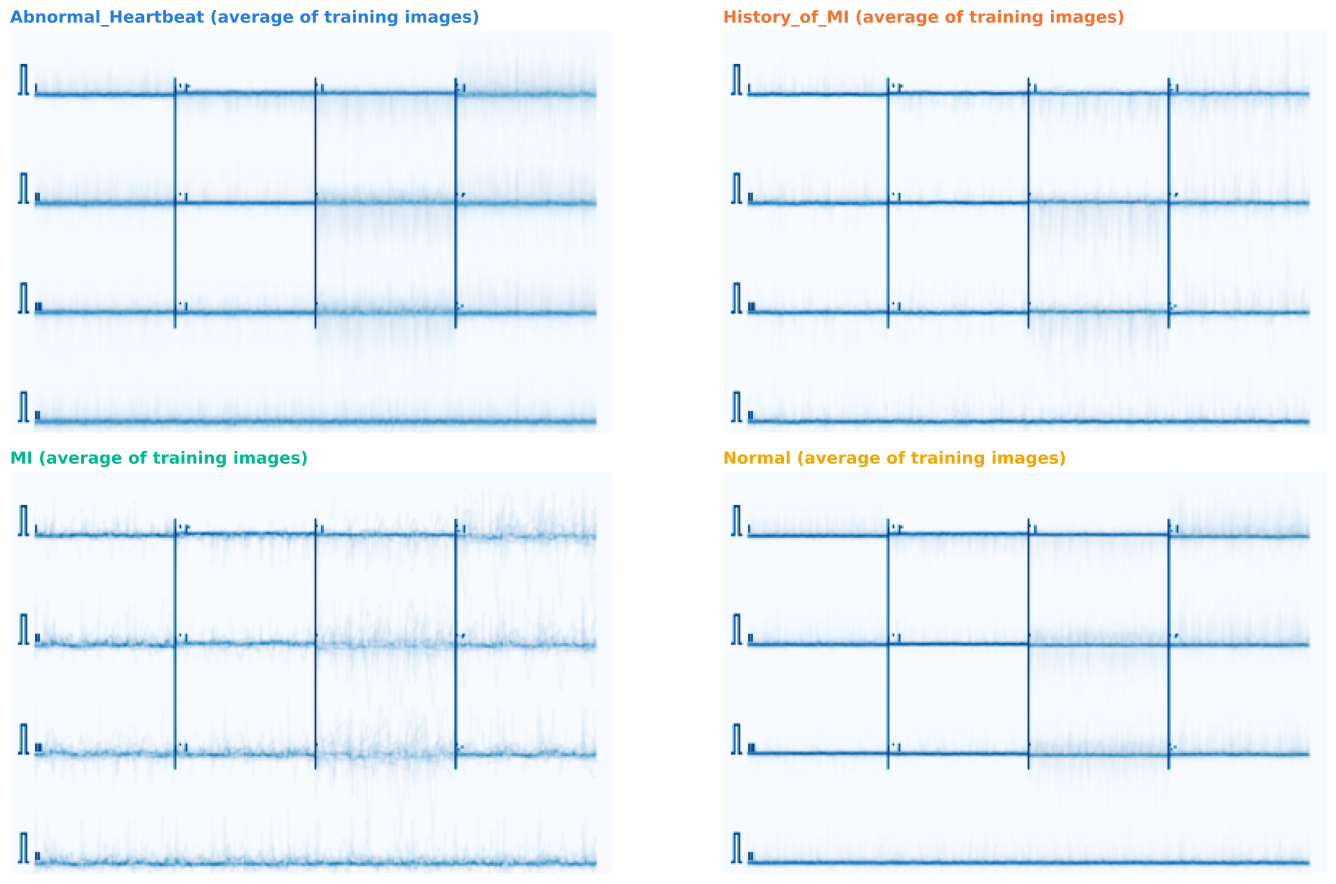

In [8]:
# Visualisation 4: the average cleaned trace per class
mean_traces = {}
for cls in CLASSES:
    paths = df[(df['label'] == cls) & (df['split'] == 'train')]['path']
    mean_traces[cls] = np.mean([preprocessing.clean_trace(preprocessing.load_rgb(p)) for p in paths], axis=0)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
vmax = max(m.max() for m in mean_traces.values())
for ax, cls in zip(axes.ravel(), CLASSES):
    ax.imshow(mean_traces[cls], cmap='Blues', vmin=0, vmax=vmax)
    ax.set_title(f'{cls} (average of training images)', loc='left', color=COLORS[cls], fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()

**Interpretation 4: the average sheet per class.** Averaging every cleaned training image of a class shows where traces agree and where they spread out. `Normal` gives the sharpest lines: healthy patients' beats look alike, so they stack neatly. `MI` is smeared across almost every lead, which fits the many different shapes an acute infarct produces depending on where it is. `History_of_MI` shows a shadow *below* the baseline in the third column (leads V1 to V3). That fits the deep Q waves an old anterior heart attack can leave, though I can't confirm the cause from averages alone. `Abnormal_Heartbeat` is blurriest in the long rhythm strip at the bottom, because beats arriving at irregular times don't line up from patient to patient.

**What the data says overall:** the classes differ in *where* and *how* the trace bends in particular leads, not in brightness or image size (all 928 sheets are 2213 x 1572). That points to features that keep track of position and edge direction, which is what HOG does, and it explains why squeezing the whole page into a small square failed.

## 4. Data processing

My first attempt fed the whole sheet, shrunk to 224 x 224, into MobileNetV2. The sheets are 2213 x 1572, so shrinking them that much wipes out the thin trace while the printed header text stays readable. The model ended up with 33% test accuracy (see section 5). So the preprocessing now works on the trace itself:

1. **Crop** to the ECG grid. This drops the patient header and footer text, which carry no heart information and could leak hints such as dates or IDs.
2. **Keep the dark pixels** (grayscale below 80). The trace is near-black and the grid is pink or light grey, so this separates them.
3. **Morphological opening** (3 x 3) removes the small grid dots that are dark enough to pass step 2.
4. **Dilate** (5 x 5) to thicken the trace so it survives resizing.
5. **Resize** to 384 x 256 with area interpolation, which averages pixels instead of skipping them.
6. **HOG features**: the image is cut into 16 x 16 cells and each cell is described by the directions of its edges. A Q wave, an ST shift or an irregular rhythm all change those edge directions in specific leads. This gives 12,420 numbers per image.
7. **Standardise and PCA** to 256 components inside the model (fitted on training data only).

There is no data augmentation. Flipping would reverse time on an ECG, and the trace positions are fixed by the printer layout, so shifting or rotating would only add noise.

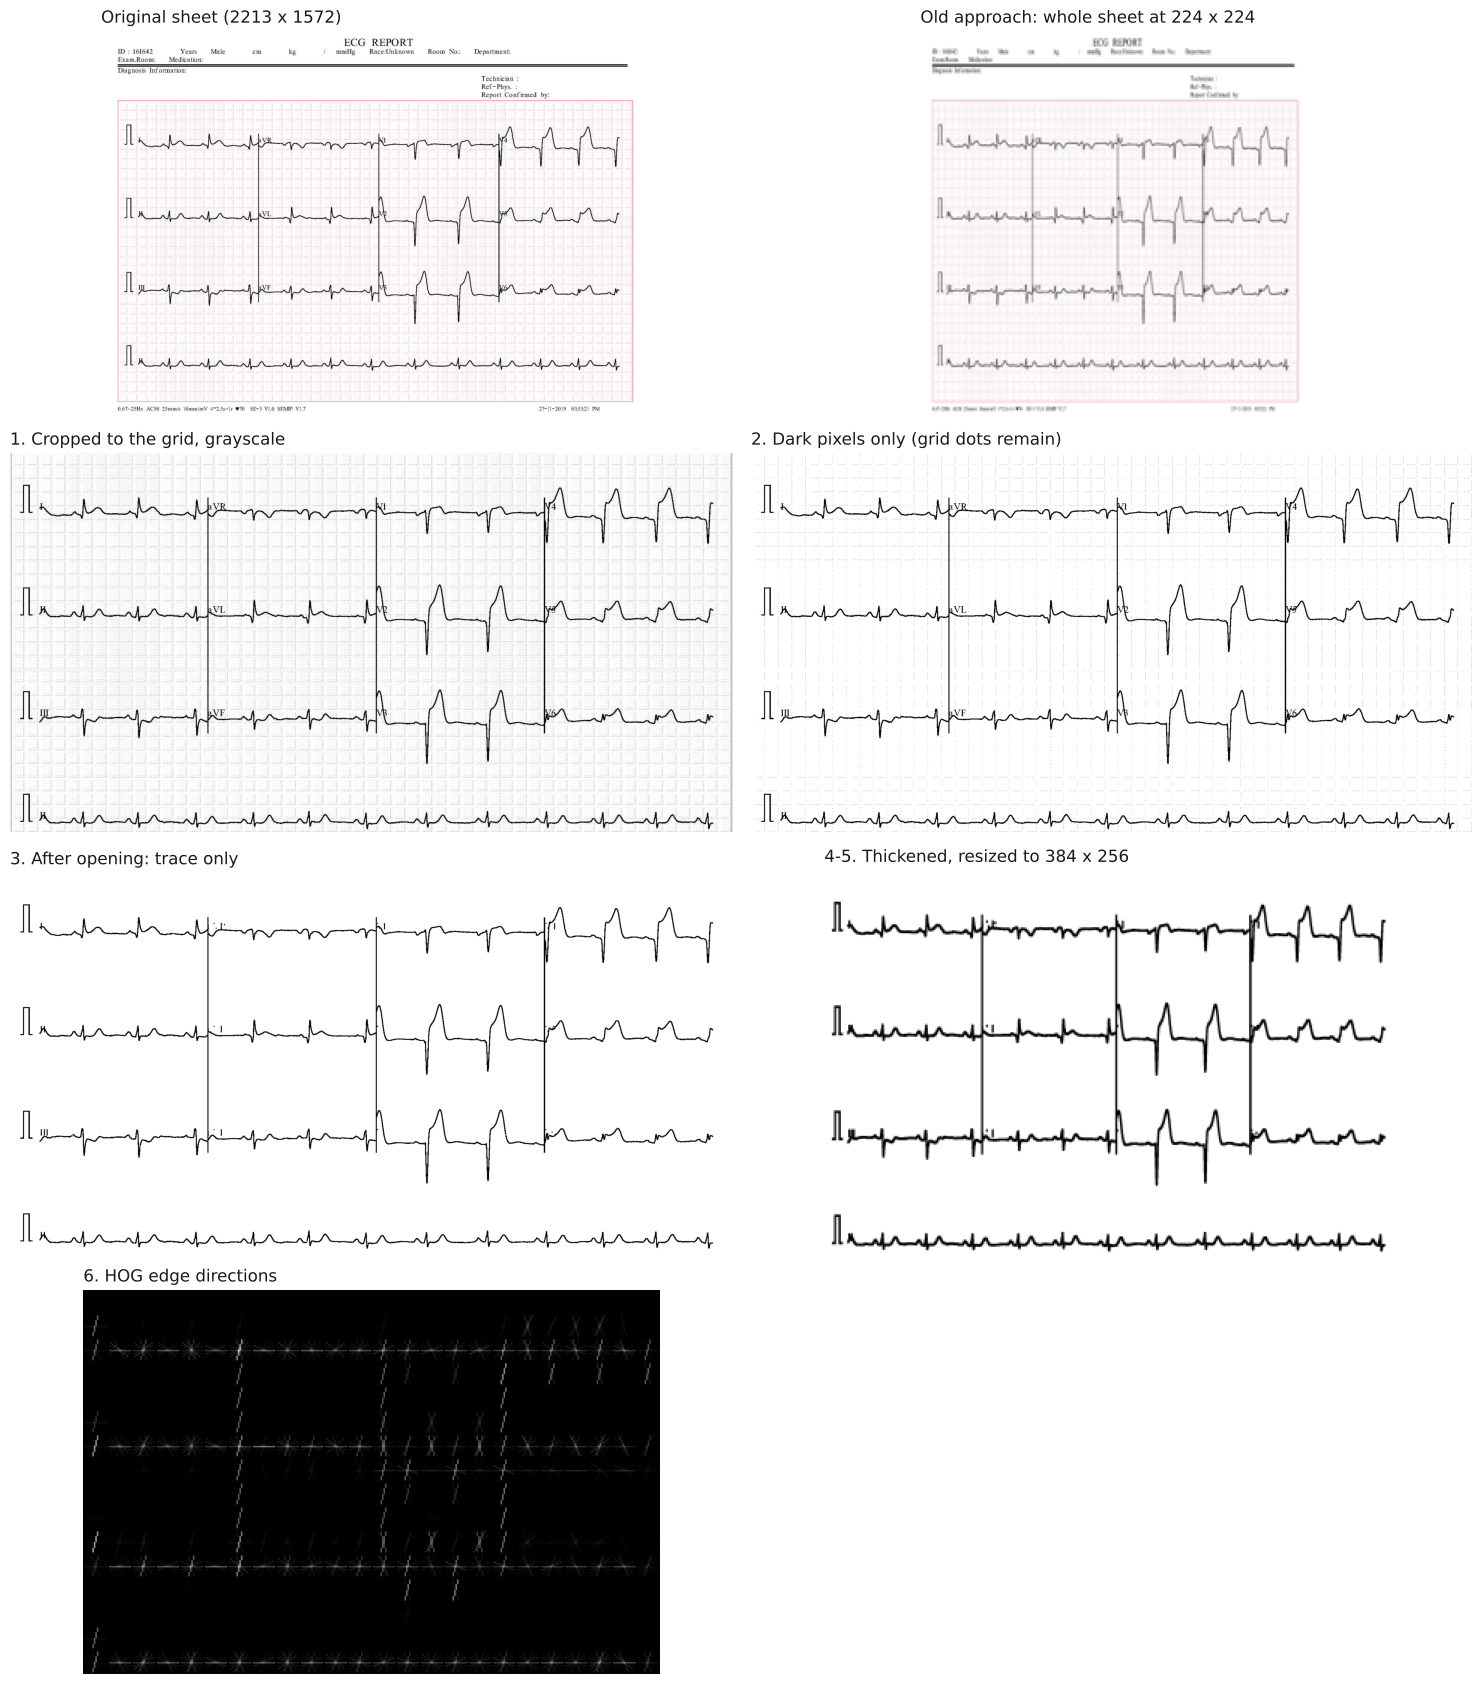

HOG feature length: 12420


In [9]:
# Every preprocessing step on one image
import cv2
from skimage.feature import hog

p = df[df['label'] == 'MI'].sample(1, random_state=1)['path'].iloc[0]
rgb = preprocessing.load_rgb(p)
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
h, w = gray.shape
t, b, l, r = preprocessing.CROP
crop = gray[int(h * t):int(h * b), int(w * l):int(w * r)]
raw_ink = (crop < preprocessing.INK_THRESHOLD).astype(np.uint8)
mask = preprocessing.trace_mask(rgb)
clean = preprocessing.clean_trace(rgb)
_, hog_img = hog(clean, visualize=True, **preprocessing.HOG_PARAMS)
naive = np.asarray(Image.fromarray(rgb).resize((224, 224)))

steps = [(rgb, 'Original sheet (2213 x 1572)'), (naive, 'Old approach: whole sheet at 224 x 224'),
         (crop, '1. Cropped to the grid, grayscale'), (1 - raw_ink, '2. Dark pixels only (grid dots remain)'),
         (1 - mask, '3. After opening: trace only'), (255 - clean, '4-5. Thickened, resized to 384 x 256'),
         (hog_img, '6. HOG edge directions')]
fig, axes = plt.subplots(4, 2, figsize=(15, 17))
for ax, (img, title) in zip(axes.ravel(), steps):
    ax.imshow(img, cmap='gray' if img.ndim == 2 else None)
    ax.set_title(title, loc='left')
    ax.axis('off')
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()
print('HOG feature length:', preprocessing.hog_features(clean).shape[0])

In [10]:
# Feature extraction for all images (cached in data/features_cache.npz, reused by retraining)
t0 = time.time()
X_train = preprocessing.features_from_paths(train_paths, config.FEATURE_CACHE_PATH)
X_test = preprocessing.features_from_paths(test_paths, config.FEATURE_CACHE_PATH)
y_train, y_test = np.array(train_labels), np.array(test_labels)
print(f'X_train {X_train.shape}, X_test {X_test.shape}  ({time.time() - t0:.0f}s)')

X_train (742, 12420), X_test (186, 12420)  (0s)


## 5. Model creation

### First attempt: MobileNetV2 transfer learning (kept as a record)

The first version of this notebook trained MobileNetV2 (ImageNet weights) on whole sheets resized to 224 x 224, with a frozen-base phase and then fine-tuning of the top 30 layers. Results on the same test set:

| Metric | Value |
|---|---|
| Accuracy | 0.328 |
| Macro F1 | 0.206 |
| ROC-AUC (macro, one-vs-rest) | 0.685 |

It predicted almost everything as `Abnormal_Heartbeat` or `MI` and never predicted `Normal` or `History_of_MI`. Two problems caused this. The trace was mostly lost at 224 x 224, so the frozen ImageNet features had little to work with (validation accuracy stalled at about 45%). Then, when fine-tuning started, training loss jumped from 1.2 to 2.8 while validation loss barely moved. That pattern means the BatchNorm layers switched to training mode on small batches and threw off the pretrained features. The test above showed that the information is in the trace, so I changed the preprocessing and the model instead of patching the CNN.

### Comparing models on the new features

Before testing anything, I compared three models with 5-fold cross-validation on the **training set only**: logistic regression, an RBF support vector machine and a neural network (MLP). Each uses the same standardise + PCA(256) step. The test set is not touched here.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

candidates = {
    'Logistic regression': LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced'),
    'SVM (RBF)': SVC(C=10, class_weight='balanced'),
    'Neural network (MLP 512-128)': MLPClassifier((512, 128), alpha=1e-2, early_stopping=True,
                                                  n_iter_no_change=15, max_iter=300, random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, clf in candidates.items():
    pipe = make_pipeline(StandardScaler(), PCA(256, random_state=SEED), clf)
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'f1_macro'], n_jobs=1)
    rows.append({'model': name, 'cv_accuracy': s['test_accuracy'].mean(), 'cv_accuracy_std': s['test_accuracy'].std(),
                 'cv_f1_macro': s['test_f1_macro'].mean(), 'fit_seconds': s['fit_time'].mean()})
cv_results = pd.DataFrame(rows).set_index('model').round(3)
display(cv_results)

,cv_accuracy,cv_accuracy_std,cv_f1_macro,fit_seconds
model,,,,
Logistic regression,0.952,0.023,0.947,0.703
SVM (RBF),0.960,0.006,0.956,0.693
Neural network (MLP 512-128),0.931,0.030,0.926,0.894


**Reading the comparison.** All three models do well on the new features, which confirms that the preprocessing was the real fix. The SVM scores slightly highest in cross-validation (0.960 accuracy, 0.956 macro F1), then logistic regression (0.952) and the MLP (0.931). I still chose the **neural network** for deployment, for one practical reason: the assignment needs retraining that starts from the saved model, and an MLP can continue training from its saved weights on new data. An SVM has to be refitted from scratch every time. The gap is small, and the final MLP below gets 0.946 test accuracy, because it trains epoch by epoch with class weights and keeps its best epoch, where the cross-validated version uses scikit-learn's default early stopping.

### Final model

`src/model.py` wraps the chosen network in an `EcgClassifier` class so the same object can be trained, saved, loaded by the API and retrained later.

**Optimisation techniques used**
- **Feature engineering**: trace extraction and HOG (section 4), the biggest single improvement.
- **PCA** to 256 components, which cuts 12,420 features down so the network does not overfit 742 images.
- **L2 regularisation** (`alpha = 0.01`) on the network weights.
- **Class weights** (balanced sample weights), so the smaller `History_of_MI` class counts as much as the others.
- **Adam optimiser** with a 0.001 learning rate and mini-batches of 32.
- **Early stopping** on a 15% validation split (patience 15 epochs), restoring the weights from the best epoch.
- **Lower learning rate for retraining** (0.0003), starting from the saved weights.

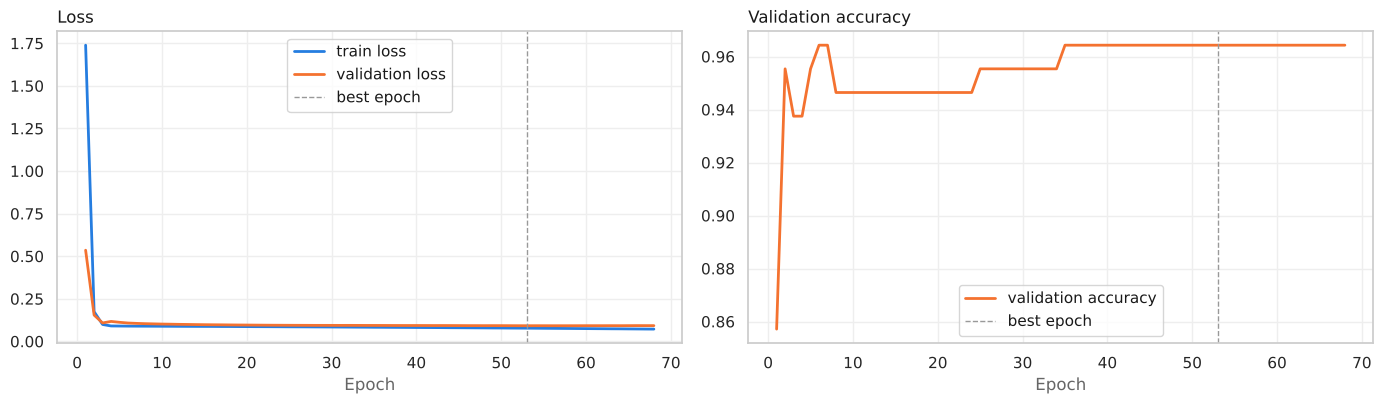

Trained 68 epochs in 4s. Best epoch 53: val_loss 0.092, val_accuracy 0.964 (weights restored from this epoch)


In [12]:
t0 = time.time()
model = EcgClassifier(class_names=CLASSES, n_components=256, hidden=(512, 128), alpha=1e-2,
                      learning_rate=1e-3, seed=SEED)
model.fit(X_train, train_labels, max_epochs=200, patience=15, val_fraction=0.15)
hist = pd.DataFrame(model.history)
best = hist.loc[hist['val_loss'].idxmin()]
print(f'Trained {len(hist)} epochs in {time.time() - t0:.0f}s. Best epoch {int(best.epoch)}: '
      f'val_loss {best.val_loss:.3f}, val_accuracy {best.val_accuracy:.3f} (weights restored from this epoch)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(hist['epoch'], hist['train_loss'], color='#257de0', lw=2, label='train loss')
axes[0].plot(hist['epoch'], hist['val_loss'], color='#f47230', lw=2, label='validation loss')
axes[0].axvline(best.epoch, color='#999999', ls='--', lw=1, label='best epoch')
axes[0].set_title('Loss', loc='left'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(hist['epoch'], hist['val_accuracy'], color='#f47230', lw=2, label='validation accuracy')
axes[1].axvline(best.epoch, color='#999999', ls='--', lw=1, label='best epoch')
axes[1].set_title('Validation accuracy', loc='left'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Model testing and evaluation

Everything below is measured on the 186 held-out test images, which the model has never seen.

In [13]:
metrics = evaluate_model(model, X_test, test_labels)
headline = {k: metrics[k] for k in ['accuracy', 'test_loss', 'precision_macro', 'recall_macro', 'f1_macro',
                                    'precision_weighted', 'recall_weighted', 'f1_weighted', 'roc_auc_ovr_macro']}
display(pd.Series(headline, name='test set').round(4))

y_prob = model.predict_proba(X_test)
y_pred = np.array(CLASSES)[y_prob.argmax(axis=1)]
print(classification_report(y_test, y_pred, digits=3))

compare = pd.DataFrame({'MobileNetV2 (first attempt)': [0.328, 0.206, 0.685],
                        'Trace + HOG + MLP (final)': [metrics['accuracy'], metrics['f1_macro'], metrics['roc_auc_ovr_macro']]},
                       index=['accuracy', 'macro F1', 'ROC-AUC']).round(3)
display(compare)

,test set
accuracy,0.9462
test_loss,0.2662
precision_macro,0.9473
recall_macro,0.9396
f1_macro,0.9425
precision_weighted,0.9478
recall_weighted,0.9462
f1_weighted,0.9460
roc_auc_ovr_macro,0.9926


                    precision    recall  f1-score   support

Abnormal_Heartbeat      0.977     0.894     0.933        47
     History_of_MI      0.909     0.882     0.896        34
                MI      1.000     1.000     1.000        48
            Normal      0.903     0.982     0.941        57

          accuracy                          0.946       186
         macro avg      0.947     0.940     0.943       186
      weighted avg      0.948     0.946     0.946       186



,MobileNetV2 (first attempt),Trace + HOG + MLP (final)
accuracy,0.328,0.946
macro F1,0.206,0.943
ROC-AUC,0.685,0.993


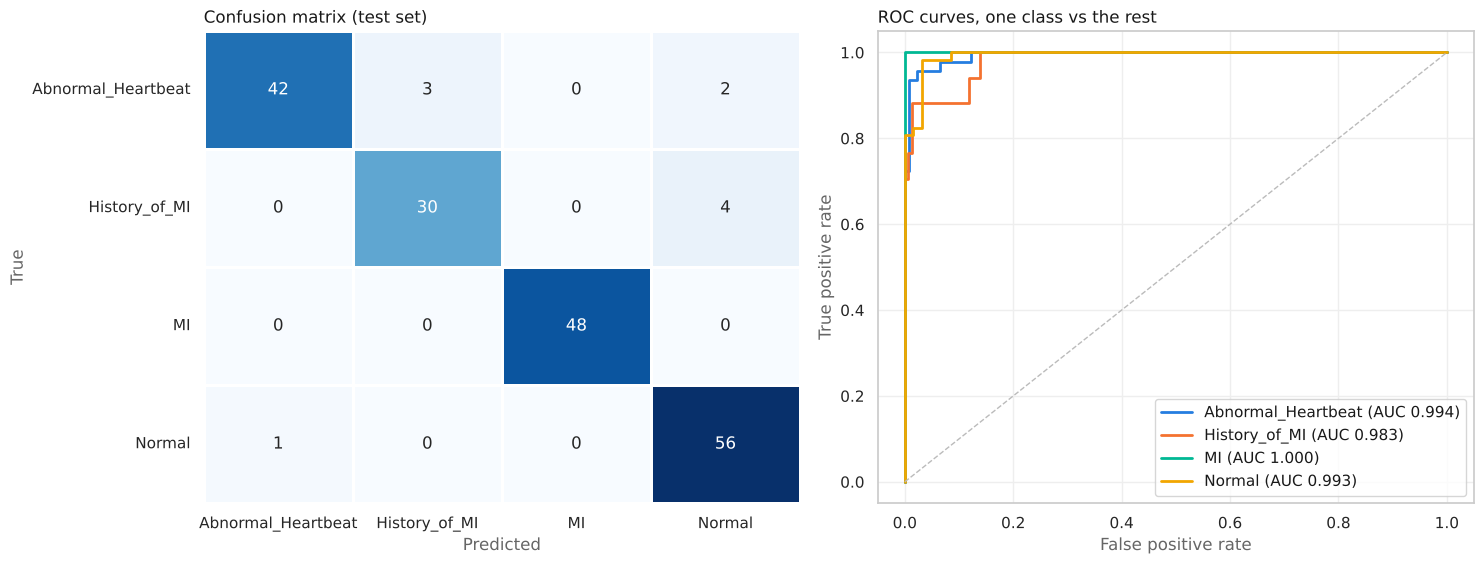

10 of 186 test images misclassified:
true                predicted         
History_of_MI       Normal                4
Abnormal_Heartbeat  History_of_MI         3
                    Normal                2
Normal              Abnormal_Heartbeat    1


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
cm = confusion_matrix(y_test, y_pred, labels=CLASSES)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=CLASSES, yticklabels=CLASSES,
            linewidths=2, linecolor='white', ax=axes[0])
axes[0].set_title('Confusion matrix (test set)', loc='left')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

for i, cls in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve((y_test == cls).astype(int), y_prob[:, i])
    axes[1].plot(fpr, tpr, color=COLORS[cls], lw=2, label=f'{cls} (AUC {auc(fpr, tpr):.3f})')
axes[1].plot([0, 1], [0, 1], color='#bbbbbb', ls='--', lw=1)
axes[1].set_title('ROC curves, one class vs the rest', loc='left')
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

wrong = pd.DataFrame({'true': y_test, 'predicted': y_pred})
wrong = wrong[wrong.true != wrong.predicted]
print(f'{len(wrong)} of {len(y_test)} test images misclassified:')
print(wrong.value_counts().rename('count').to_string())

**Reading the results.** On 186 unseen test images the model gets **94.6% accuracy, 0.943 macro F1 and 0.993 macro ROC-AUC**, up from 32.8%, 0.206 and 0.685 with the first MobileNetV2 attempt, and above the 0.80 ROC-AUC of my tabular summative. `MI` is the easiest class: all 48 test cases are correct, with precision and recall of 1.00. `History_of_MI` is the hardest (recall 0.88): 4 of its 34 cases were called `Normal`. That mistake makes clinical sense. Once a heart attack has healed, the remaining signs can be subtle (a Q wave in a few leads), so an old-MI ECG can look close to a normal one. The other errors are 5 `Abnormal_Heartbeat` sheets called `History_of_MI` or `Normal`, likely patients whose irregular beats were rare on that strip, and 1 `Normal` called abnormal. No acute `MI` was missed and nothing was wrongly called `MI`, which would be the most dangerous mistake. The main limitation is size: one hospital, one printer layout and one split, so each test error moves accuracy by about 0.5 points.

## 7. Save the model and artefacts

In [15]:
os.makedirs(config.MODEL_DIR, exist_ok=True)
model.save(config.MODEL_PATH)
with open(config.CLASS_NAMES_PATH, 'w') as f:
    json.dump(CLASSES, f)
saved_metrics = dict(metrics, source='notebook', updated_at=pd.Timestamp.utcnow().isoformat(timespec='seconds'))
with open(config.METRICS_PATH, 'w') as f:
    json.dump(saved_metrics, f, indent=2)
for name in sorted(os.listdir(config.MODEL_DIR)):
    full = os.path.join(config.MODEL_DIR, name)
    if os.path.isfile(full) and not name.startswith('.'):
        print(f'{name:22s} {os.path.getsize(full) / 1e6:6.2f} MB')

class_names.json         0.00 MB
ecg_hog_mlp.pkl         16.25 MB
test_metrics.json        0.00 MB


## 8. Prediction function

`predict_image` in `src/prediction.py` takes an image file, runs the same preprocessing and returns the class, the confidence and all four probabilities. The API's `/predict` endpoint calls the same code with the uploaded bytes. Here the model is reloaded from disk first, to prove the saved file works on its own.

In [16]:
from src.prediction import predict_image

reloaded = load_model(config.MODEL_PATH)
same = np.allclose(reloaded.predict_proba(X_test[:20]), model.predict_proba(X_test[:20]))
print('Reloaded model gives identical probabilities:', same)

rng = random.Random(7)
sample = rng.sample(list(zip(test_paths, test_labels)), 8)
rows = []
for path, true in sample:
    t0 = time.time()
    out = predict_image(path)
    rows.append({'file': os.path.basename(path), 'true': true, 'predicted': out['prediction'],
                 'confidence': round(out['confidence'], 3), 'correct': out['prediction'] == true,
                 'ms': round((time.time() - t0) * 1000)})
display(pd.DataFrame(rows))

Reloaded model gives identical probabilities: True


,file,true,predicted,confidence,correct,ms
0,MI(108).jpg,MI,MI,1.000,True,39
1,HB(54).jpg,Abnormal_Heartbeat,Abnormal_Heartbeat,1.000,True,30
2,MI(177).jpg,MI,MI,1.000,True,33
3,Normal(25).jpg,Normal,Normal,0.999,True,30
4,HB(153).jpg,Abnormal_Heartbeat,Abnormal_Heartbeat,1.000,True,36
5,HB(180).jpg,Abnormal_Heartbeat,Abnormal_Heartbeat,1.000,True,36
6,Normal(127).jpg,Normal,Normal,1.000,True,31
7,HB(220).jpg,Abnormal_Heartbeat,Abnormal_Heartbeat,0.998,True,31


## 9. Retraining check

Retraining in the app (`src/retrain.py`) loads the **saved model** as the starting point and keeps training on the old plus new images at a lower learning rate. The scaler and PCA stay fixed, so the network continues from its saved weights instead of starting over. Here the same call runs on a copy of the model, with no new data, just to confirm it works end to end. The saved file is not changed.

In [17]:
retrain_copy = load_model(config.MODEL_PATH)
before = evaluate_model(retrain_copy, X_test, test_labels)
w_before = retrain_copy.mlp.coefs_[0].copy()
epochs_before = len(retrain_copy.history)
retrain_copy.continue_training(X_train, train_labels, learning_rate=3e-4, max_epochs=40, patience=8)
after = evaluate_model(retrain_copy, X_test, test_labels)
print(f'Continued from epoch {epochs_before} to epoch {len(retrain_copy.history)}; '
      f'weights changed: {not np.allclose(w_before, retrain_copy.mlp.coefs_[0])}')
display(pd.DataFrame({'before': {k: before[k] for k in ['accuracy', 'f1_macro', 'roc_auc_ovr_macro']},
                      'after': {k: after[k] for k in ['accuracy', 'f1_macro', 'roc_auc_ovr_macro']}}).round(3))

Continued from epoch 68 to epoch 80; weights changed: True


,before,after
accuracy,0.946,0.952
f1_macro,0.943,0.947
roc_auc_ovr_macro,0.993,0.993


## 10. Limitations

- **Small, single-source dataset.** 928 sheets from one hospital and one printer layout. The crop box and ink threshold assume that layout, so photos of paper ECGs or other machines would need a different front end.
- **One train/test split.** The cross-validation spread in section 5 gives a sense of the variance, but 186 test images means each mistake moves accuracy by about half a point.
- **Not a diagnostic tool.** This is a study project. A real system would need clinical validation, much more data and per-lead analysis.